# **CB 1 Metode Numerik (File `.ipynb`)**

In [17]:
# setup
import numpy as np
import scipy as sp
import matplotlib.pyplot as plt

### **0. Tampilan Plotting Fungsi non Linear** 

Fungsi non linier yang dipakai:

$$f(x) = e^{-5x} \ . \ \cos(3x) - 0.2$$

In [18]:
# fungsi non linier yang dipakai (dalam bentuk program)

f = lambda x: np.exp(-5*x) * np.cos(3*x) - 0.2

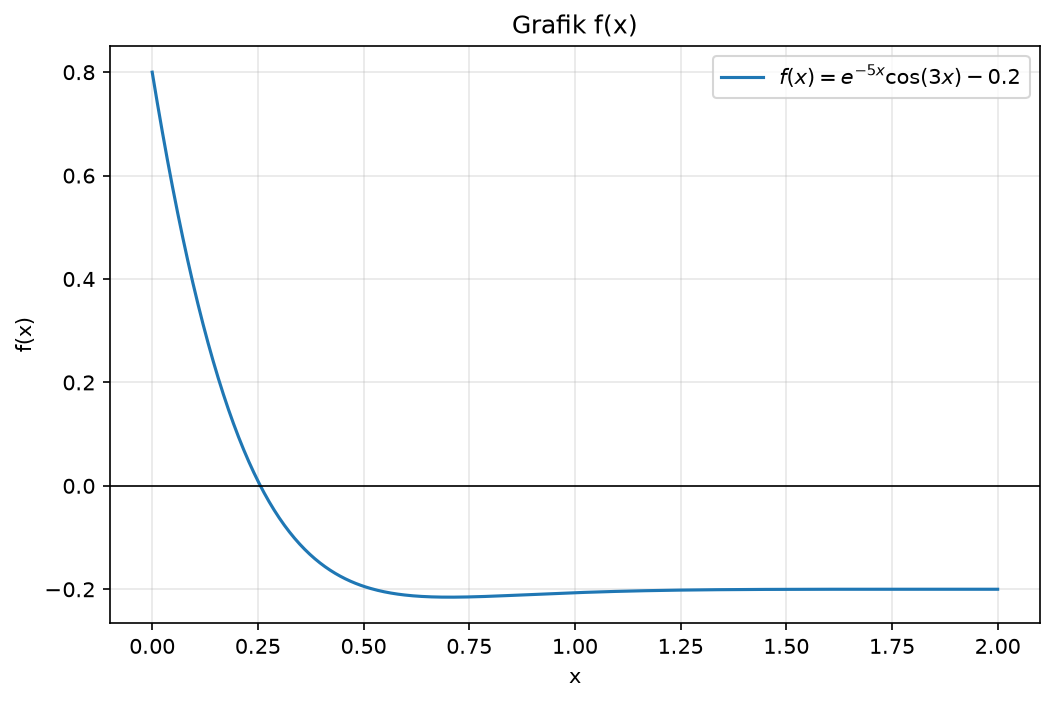

In [38]:
# plotting

x = np.linspace(0, 2, 500)   # 500 titik dari 0 sampai 2
y = f(x)

plt.subplots(figsize=(8, 5))
plt.plot(x, y, label=r"$f(x)=e^{-5x}\cos(3x)-0.2$", color="tab:blue")
plt.axhline(0, color="black", linewidth=0.8)
plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("Grafik f(x)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

### 1. Implementasi *Algoritma Bisection* didalam Kode Program Python

In [19]:
# function (dalam definisi programming) untuk kalkulasi bisection (copas dari slide)
# + tambahan penjelasan setiap baris di iterasi

def bisection(f, a, b, es=0.5):
    if f(a) * f(b) >= 0:
        print("Penentuan a dan b salah"); return None
    cp = None # nilai tengah sebelumnya
    n = 0 # iterasi
    print("n\ta\t\tb\t\tc\t\tf(c)\t\tEr(%)") # print tabel kolom diatas
    while True:
        c = (a + b) / 2
        er = None if cp is None else abs((c - cp) / c) * 100
        print(f"{n}\t{a:.6f}\t{b:.6f}\t{c:.6f}\t{f(c):.6f}\t{'-' if er is None else format(er,'.4f')}")
        if er is not None and er < es:
            return c
        if f(a) * f(c) < 0: b = c
        else: a = c
        cp = c; n += 1

bisection(f, 0, 1)

n	a		b		c		f(c)		Er(%)
0	0.000000	1.000000	0.500000	-0.194194	-
1	0.000000	0.500000	0.250000	0.009632	100.0000
2	0.250000	0.500000	0.375000	-0.133877	33.3333
3	0.250000	0.375000	0.312500	-0.075951	20.0000
4	0.250000	0.312500	0.281250	-0.037117	11.1111
5	0.250000	0.281250	0.265625	-0.014798	5.8824
6	0.250000	0.265625	0.257812	-0.002855	3.0303
7	0.250000	0.257812	0.253906	0.003319	1.5385
8	0.253906	0.257812	0.255859	0.000215	0.7634
9	0.255859	0.257812	0.256836	-0.001325	0.3802


0.2568359375

### 2. Implementasi *Algoritma Newton* didalam Kode Program Python

In [25]:
# turunan untuk fungsi
df = lambda x: sp.differentiate.derivative(f, x).df

In [28]:
def newton(f, df, x0, es=0.5, nmax=50):
    x = x0
    print("n\txi\t\tf(xi)\t\tf'(xi)\t\txi+1\t\tEr(%)")
    for k in range(nmax):
        xn = x - f(x) / df(x)
        er = abs((xn - x) / xn) * 100
        print(f"{k}\t{x:.6f}\t{f(x):.6f}\t{df(x):.6f}\t{xn:.6f}\t{er:.6f}")
        if er < es:
            return xn
        x = xn
    return x

newton(f, df, 0.4, 0.5)

n	xi		f(xi)		f'(xi)		xi+1		Er(%)
0	0.400000	-0.150960	-0.623612	0.157926	153.282912
1	0.157926	0.204003	-2.641448	0.235158	32.842457
2	0.235158	0.034920	-1.774836	0.254833	7.720771
3	0.254833	0.001842	-1.589942	0.255992	0.452632


np.float64(0.2559915105610779)